In [1]:
import py4hw
class nBitAdder(py4hw.Logic):
    def __init__(self, parent, name, x, y, ci, r, co):
        super().__init__(parent, name)
        x  = self.addIn('x', x)
        y  = self.addIn('y', y)
        ci = self.addIn('ci', ci)
        r  = self.addOut('r', r)
        co = self.addOut('co', co)

        n = x.getWidth()

        carry = ci          
        sbits = []          
        i = 0

        while i < n:
            xi = self.wire(f'x{i}')
            yi = self.wire(f'y{i}')
            si = self.wire(f's{i}')
            cnext = self.wire(f'c{i+1}')

            py4hw.Bit(self, f'bitx{i}', x, i, xi)
            py4hw.Bit(self, f'bity{i}', y, i, yi)
            FullAdder(self, f'fa{i}', xi, yi, carry, si, cnext)

            sbits.append(si)
            carry = cnext  
            i += 1

        py4hw.ConcatenateLSBF(self, 'cat', sbits, r)
        py4hw.Buf(self, 'bufco', carry, co)

In [2]:
class FullAdder(py4hw.Logic):
    
    def __init__(self, parent, name, x, y, ci, s, co):
        super().__init__(parent, name)
        
        x = self.addIn('x', x)
        y = self.addIn('y', y)
        ci = self.addIn('ci', ci)
        s = self.addOut('s', s)
        co = self.addOut('co', co)

        w1 = self.wire('w1',1)
        w2 = self.wire('w2',1)
        w3 = self.wire('w3',1)
        
        py4hw.Xor2(self, 'g1', x, y, w1)
        py4hw.Xor2(self, 'g2', w1, ci, s)
        py4hw.And2(self, 'g3', w1, ci, w2)
        py4hw.And2(self, 'g4', x, y, w3)
        py4hw.Or2(self, 'g5', w2, w3, co)


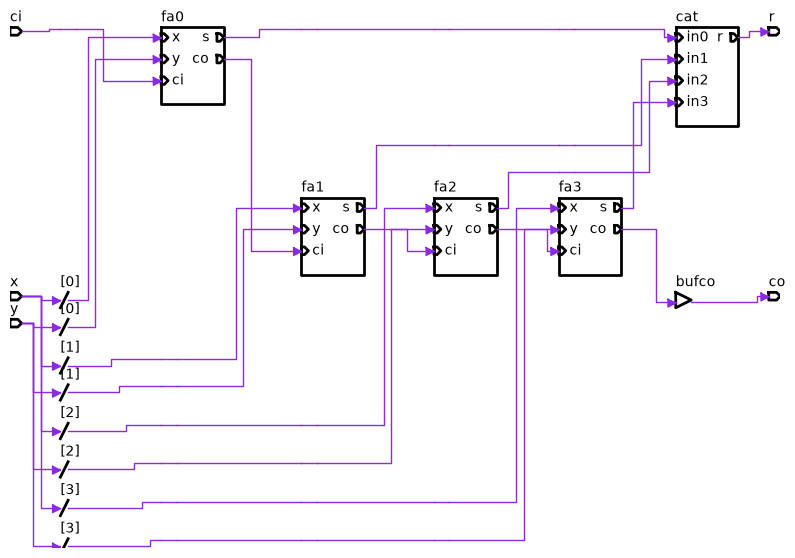

In [3]:
hw = py4hw.HWSystem()
x  = hw.wire('x', 4)      
y  = hw.wire('y', 4)
r  = hw.wire('r', 4)
ci = hw.wire('ci')
co = hw.wire('co')

py4hw.Constant(hw, 'cci', 0, ci)
NBit = nBitAdder(hw, 'NBit', x, y, ci, r, co)  

sch = py4hw.Schematic(NBit)
sch.draw()